# Phase 5 - Super-Clustering Contextual (Transformer)

Este notebook entrena un encoder temporal auto-supervisado sobre secuencias de tokens (silabas),
extrae embeddings contextuales y construye regimenes mediante clustering en ese espacio.

In [1]:
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 240)
pd.set_option('display.width', 260)


In [2]:
# =========================
# Config
# =========================
SYMBOL = 'GBPUSD'
MODEL_TAG = 'v2'
SEQ_LEN = 32
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

# Transformer
D_MODEL = 96
N_HEAD = 4
N_LAYERS = 3
FF_DIM = 192
DROPOUT = 0.12
EMB_DIM = 64
DELTA_BINS = 24
SIGN_BINS = 3
MASK_PROB = 0.15
BATCH_SIZE = 64
EPOCHS = 45
LR = 8e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 10

# Super-clustering
K_CANDIDATES = list(range(4, 13))
N_INIT_KMEANS = 40
HORIZON_HOURS = 24
MIN_CLUSTER_N = 20

IN_DIR = Path('./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2')
WINDOWS_PATH = IN_DIR / 'GBPUSD_sequence_windows_full_len32.parquet'
VOCAB_PATH = IN_DIR / 'GBPUSD_token_vocabulary.json'
PRICE_PATH = Path('./data/Dataset_H1_v1/parquet_h1/GBPUSD.parquet')

OUT_DIR = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_CSV = OUT_DIR / 'GBPUSD_transformer_context_train_history.csv'
ENCODER_PT = OUT_DIR / 'GBPUSD_transformer_context_encoder.pt'
MODEL_SELECTION_CSV = OUT_DIR / 'GBPUSD_superclustering_model_selection.csv'
EMB_PQ = OUT_DIR / 'GBPUSD_context_window_embeddings.parquet'
EMB_CSV = OUT_DIR / 'GBPUSD_context_window_embeddings.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_regime_profile.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_regime_transition_matrix.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_superclustering_summary.json'

print('WINDOWS_PATH =', WINDOWS_PATH)
print('DEVICE =', DEVICE)
print('OUT_DIR =', OUT_DIR)


WINDOWS_PATH = ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_sequence_windows_full_len32.parquet
DEVICE = cuda
OUT_DIR = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2


In [3]:
# =========================
# Reproducibilidad + helpers
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001

def temporal_split(n: int, train_ratio: float, val_ratio: float):
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + val_ratio))
    tr_end = max(1, min(tr_end, n - 2))
    va_end = max(tr_end + 1, min(va_end, n - 1))
    idx_train = np.arange(0, tr_end)
    idx_val = np.arange(tr_end, va_end)
    idx_test = np.arange(va_end, n)
    return idx_train, idx_val, idx_test

def delta_to_bins(delta_arr: np.ndarray, delta_max: float, n_bins: int):
    x = np.asarray(delta_arr, dtype=float)
    x = np.clip(x, 0.0, max(1e-6, float(delta_max)))
    z = np.log1p(x) / np.log1p(max(1e-6, float(delta_max)))
    b = np.floor(z * (n_bins - 1 + 1e-12)).astype(int)
    b = np.clip(b, 0, n_bins - 1)
    return b

def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24):
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')

    out = np.full(len(ts), np.nan, dtype=float)
    ps = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / ps
    return out

def make_masked_inputs(x: torch.Tensor, vocab_size: int, mask_id: int, mask_prob: float = 0.15):
    labels = x.clone()
    prob = torch.rand_like(x.float())
    masked = prob < mask_prob

    labels[~masked] = -100
    x_in = x.clone()

    if masked.any():
        r = torch.rand_like(x.float())
        mask_pos = masked & (r < 0.8)
        rand_pos = masked & (r >= 0.8) & (r < 0.9)

        x_in[mask_pos] = mask_id
        if rand_pos.any():
            rnd = torch.randint(low=0, high=vocab_size, size=(rand_pos.sum().item(),), device=x.device)
            x_in[rand_pos] = rnd

    return x_in, labels


In [4]:
# =========================
# Load sequence windows
# =========================
for p in [WINDOWS_PATH, VOCAB_PATH, PRICE_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Missing file: {p}')

W = pd.read_parquet(WINDOWS_PATH).copy()
W['start_ts'] = pd.to_datetime(W['start_ts'], errors='coerce')
W['end_ts'] = pd.to_datetime(W['end_ts'], errors='coerce')
W = W.sort_values(['start_ts', 'window_id']).reset_index(drop=True)

vocab = json.loads(VOCAB_PATH.read_text())
token_to_id = {str(k): int(v) for k, v in vocab['token_to_id'].items()}
id_to_token = {int(v): str(k) for k, v in token_to_id.items()}
vocab_size = len(token_to_id)
mask_id = vocab_size

# arrays
tok = np.vstack([np.array([token_to_id[str(t)] for t in row], dtype=np.int64) for row in W['token_seq']])
dlt = np.vstack([np.asarray(row, dtype=float) for row in W['delta_h_seq']])
sgn = np.vstack([np.asarray(row, dtype=int) for row in W['move_sign_seq']])
sgn = np.clip(sgn + 1, 0, 2).astype(np.int64)  # -1,0,1 -> 0,1,2

if tok.shape[1] != SEQ_LEN:
    raise RuntimeError(f'Expected seq len {SEQ_LEN}, got {tok.shape[1]}')

idx_train, idx_val, idx_test = temporal_split(len(W), TRAIN_RATIO, VAL_RATIO)
split = np.array(['train'] * len(W), dtype=object)
split[idx_val] = 'val'
split[idx_test] = 'test'
W['split'] = split

# delta bins calibrated on train only
delta_max = float(np.nanquantile(dlt[idx_train].reshape(-1), 0.99))
delta_max = max(1.0, delta_max)
dlt_bin = delta_to_bins(dlt, delta_max=delta_max, n_bins=DELTA_BINS).astype(np.int64)

print('windows =', len(W), '| vocab_size =', vocab_size)
print('split counts:')
print(W['split'].value_counts().to_string())
print('delta_max(train p99) =', round(delta_max, 3))
display(W.head(3))


windows = 1605 | vocab_size = 9
split counts:
split
train    1123
val       241
test      241
delta_max(train p99) = 780.0


,window_id,symbol,seq_len,start_ts,end_ts,token_seq,cluster_seq,delta_h_seq,move_sign_seq,split
0,0,GBPUSD,32,2000-05-31 10:00:00,2000-11-01 23:00:00,"[c03, c01, c08, c07, c01, c01, c02, c01, c08, ...","[3, 1, 8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, ...","[0.0, 40.0, 144.0, 114.0, 50.0, 336.0, 319.0, ...","[1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, ...",train
1,1,GBPUSD,32,2000-06-02 02:00:00,2000-11-02 23:00:00,"[c01, c08, c07, c01, c01, c02, c01, c08, c07, ...","[1, 8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, 4, ...","[40.0, 144.0, 114.0, 50.0, 336.0, 319.0, 189.0...","[1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, 1, ...",train
2,2,GBPUSD,32,2000-06-08 02:00:00,2000-11-06 02:00:00,"[c08, c07, c01, c01, c02, c01, c08, c07, c01, ...","[8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, 4, 7, ...","[144.0, 114.0, 50.0, 336.0, 319.0, 189.0, 192....","[-1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, 1, -1,...",train


In [5]:
# =========================
# Dataset + model
# =========================
class SeqDataset(Dataset):
    def __init__(self, tok_arr, dlt_arr, sgn_arr, indices):
        idx = np.asarray(indices, dtype=int)
        self.tok = torch.from_numpy(tok_arr[idx]).long()
        self.dlt = torch.from_numpy(dlt_arr[idx]).long()
        self.sgn = torch.from_numpy(sgn_arr[idx]).long()

    def __len__(self):
        return len(self.tok)

    def __getitem__(self, i):
        return self.tok[i], self.dlt[i], self.sgn[i]


class ContextTransformer(nn.Module):
    def __init__(self, vocab_size, mask_id, seq_len, d_model, n_head, n_layers, ff_dim, dropout, delta_bins, sign_bins, emb_dim):
        super().__init__()
        self.vocab_size = int(vocab_size)
        self.mask_id = int(mask_id)
        self.seq_len = int(seq_len)

        self.token_emb = nn.Embedding(vocab_size + 1, d_model)  # +1 mask token
        self.delta_emb = nn.Embedding(delta_bins, d_model)
        self.sign_emb = nn.Embedding(sign_bins, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, emb_dim),
        )
        self.mlm_head = nn.Linear(d_model, vocab_size)

    def forward(self, tok_ids, dlt_ids, sgn_ids):
        h = self.token_emb(tok_ids) + self.delta_emb(dlt_ids) + self.sign_emb(sgn_ids)
        h = h + self.pos_emb[:, :h.shape[1], :]
        h = self.encoder(h)
        logits = self.mlm_head(h)

        pooled = h.mean(dim=1)
        z = self.to_emb(pooled)
        return logits, z


In [6]:
# =========================
# Train contextual encoder (MLM)
# =========================
pin = DEVICE == 'cuda'
train_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, idx_train), batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin)
val_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, idx_val), batch_size=BATCH_SIZE, shuffle=False, pin_memory=pin)

model = ContextTransformer(
    vocab_size=vocab_size,
    mask_id=mask_id,
    seq_len=SEQ_LEN,
    d_model=D_MODEL,
    n_head=N_HEAD,
    n_layers=N_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    delta_bins=DELTA_BINS,
    sign_bins=SIGN_BINS,
    emb_dim=EMB_DIM,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=-100)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=LR * 0.05)

history = []
best_val = float('inf')
best_state = None
bad = 0

for ep in range(1, EPOCHS + 1):
    model.train()
    tr_losses = []

    for xb_tok, xb_dlt, xb_sgn in train_loader:
        xb_tok = xb_tok.to(DEVICE, non_blocking=True)
        xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
        xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)

        x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)

        opt.zero_grad(set_to_none=True)
        logits, _ = model(x_in, xb_dlt, xb_sgn)
        loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        tr_losses.append(float(loss.detach().cpu().item()))

    sched.step()
    tr = float(np.mean(tr_losses)) if tr_losses else np.nan

    model.eval()
    va_losses = []
    with torch.no_grad():
        for xb_tok, xb_dlt, xb_sgn in val_loader:
            xb_tok = xb_tok.to(DEVICE, non_blocking=True)
            xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
            xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
            x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)
            logits, _ = model(x_in, xb_dlt, xb_sgn)
            loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
            va_losses.append(float(loss.detach().cpu().item()))

    va = float(np.mean(va_losses)) if va_losses else np.nan

    if np.isfinite(va) and va < best_val - 1e-6:
        best_val = va
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad = 0
    else:
        bad += 1

    history.append({'epoch': ep, 'train_loss': tr, 'val_loss': va, 'lr': opt.param_groups[0]['lr']})

    if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
        print(f'ep={ep:03d} train={tr:.6f} val={va:.6f} lr={opt.param_groups[0]["lr"]:.6g}')

    if bad >= PATIENCE and ep >= 15:
        print(f'Early stopping at ep={ep}')
        break

if best_state is not None:
    model.load_state_dict(best_state)

torch.save({'state_dict': model.state_dict(), 'config': {
    'seq_len': SEQ_LEN, 'd_model': D_MODEL, 'n_head': N_HEAD, 'n_layers': N_LAYERS,
    'ff_dim': FF_DIM, 'dropout': DROPOUT, 'emb_dim': EMB_DIM, 'delta_bins': DELTA_BINS,
    'sign_bins': SIGN_BINS, 'vocab_size': vocab_size, 'mask_id': mask_id, 'delta_max': delta_max,
}}, ENCODER_PT)

HIST = pd.DataFrame(history)
HIST.to_csv(HISTORY_CSV, index=False)

print('best_val_mlm =', best_val)
print('saved encoder =', ENCODER_PT)
print('saved history =', HISTORY_CSV)


ep=001 train=1.701389 val=1.459553 lr=0.000799074


ep=005 train=1.292210 val=1.431767 lr=0.000777083


ep=010 train=1.187211 val=1.530967 lr=0.000711097


ep=015 train=1.067869 val=1.621050 lr=0.00061
Early stopping at ep=16
best_val_mlm = 1.3654648065567017
saved encoder = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_transformer_context_encoder.pt
saved history = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_transformer_context_train_history.csv


In [7]:
# =========================
# Infer contextual embeddings
# =========================
model.eval()

def encode_all(tok_arr, dlt_arr, sgn_arr, bs=256):
    out = []
    with torch.no_grad():
        for i in range(0, len(tok_arr), bs):
            xb_tok = torch.from_numpy(tok_arr[i:i+bs]).long().to(DEVICE)
            xb_dlt = torch.from_numpy(dlt_arr[i:i+bs]).long().to(DEVICE)
            xb_sgn = torch.from_numpy(sgn_arr[i:i+bs]).long().to(DEVICE)
            _, z = model(xb_tok, xb_dlt, xb_sgn)
            out.append(z.detach().cpu().numpy())
    return np.vstack(out).astype(np.float32)

Z = encode_all(tok, dlt_bin, sgn)
print('Z shape =', Z.shape)


Z shape = (1605, 64)


In [8]:
# =========================
# Super-clustering selection by temporal validation
# =========================
scaler = StandardScaler()
Z_train = scaler.fit_transform(Z[idx_train])
Z_val = scaler.transform(Z[idx_val])
Z_test = scaler.transform(Z[idx_test])

rows = []
for k in K_CANDIDATES:
    km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=SEED)
    km.fit(Z_train)
    lv = km.predict(Z_val)

    sil = np.nan
    ch = np.nan
    db = np.nan
    if len(np.unique(lv)) >= 2 and len(lv) > k:
        sil = float(silhouette_score(Z_val, lv))
        ch = float(calinski_harabasz_score(Z_val, lv))
        db = float(davies_bouldin_score(Z_val, lv))

    rows.append({'k': int(k), 'sil_val': sil, 'ch_val': ch, 'db_val': db})

SEL = pd.DataFrame(rows).sort_values(['sil_val', 'db_val'], ascending=[False, True], na_position='last').reset_index(drop=True)
SEL.to_csv(MODEL_SELECTION_CSV, index=False)
BEST_K = int(SEL.iloc[0]['k'])

print('BEST_K =', BEST_K)
display(SEL)


BEST_K = 6


,k,sil_val,ch_val,db_val
0,6,0.192109,46.180738,1.663418
1,5,0.155953,39.309065,1.810638
2,7,0.145990,37.037974,1.870249
3,4,0.130912,35.404924,2.175473
4,10,0.110483,32.446242,1.906928
5,8,0.106483,32.120338,1.708253
6,12,0.106314,30.733477,1.720641
7,11,0.057120,25.777781,1.833269
8,9,0.056244,27.563120,1.633373


In [9]:
# =========================
# Final clustering + regime profiling
# =========================
# fit on train+val for final assignment
idx_trainval = np.concatenate([idx_train, idx_val])
Z_trainval = scaler.fit_transform(Z[idx_trainval])
Z_all = scaler.transform(Z)

KM = KMeans(n_clusters=BEST_K, n_init=N_INIT_KMEANS, random_state=SEED)
KM.fit(Z_trainval)
reg = KM.predict(Z_all)
dist = KM.transform(Z_all).min(axis=1)

OUT = W[['window_id', 'symbol', 'start_ts', 'end_ts', 'split']].copy()
OUT['regime_id'] = reg.astype(int)
OUT['regime_dist'] = dist.astype(float)
OUT['regime_token'] = OUT['regime_id'].map(lambda x: f'r{x:02d}')

for j in range(Z.shape[1]):
    OUT[f'ctx_emb_{j:03d}'] = Z[:, j]

# economic profile using forward return from end_ts
PX = pd.read_parquet(PRICE_PATH, columns=['timestamp', 'close']).copy()
PX['timestamp'] = pd.to_datetime(PX['timestamp'], errors='coerce')
PX['close'] = pd.to_numeric(PX['close'], errors='coerce')
PX = PX.dropna().sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)

OUT['ret_fwd_24h_pips'] = compute_forward_pips(PX, OUT['end_ts'], symbol=SYMBOL, horizon_hours=HORIZON_HOURS)

test_mask = OUT['split'] == 'test'
test_df = OUT.loc[test_mask].copy()

prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
        .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
        .reset_index())
prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

# significance
groups = []
for rid, g in test_df.groupby('regime_id'):
    x = g['ret_fwd_24h_pips'].dropna().to_numpy()
    if len(x) >= MIN_CLUSTER_N:
        groups.append(x)

kw_p = np.nan
anova_p = np.nan
eta2 = np.nan
if len(groups) >= 2:
    kw_p = float(kruskal(*groups).pvalue)
    anova_p = float(f_oneway(*groups).pvalue)
    all_vals = np.concatenate(groups)
    gm = np.mean(all_vals)
    ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
    sst = np.sum((all_vals - gm) ** 2)
    eta2 = float(ssb / sst) if sst > 0 else np.nan

# regime transitions on full sequence
tmp = OUT.sort_values('start_ts').reset_index(drop=True)
tr = pd.crosstab(tmp['regime_token'], tmp['regime_token'].shift(-1)).fillna(0)
tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

OUT.to_parquet(EMB_PQ, index=False)
OUT.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)

summary = {
    'symbol': SYMBOL,
    'n_windows': int(len(OUT)),
    'split_counts': {k: int(v) for k, v in OUT['split'].value_counts().to_dict().items()},
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved embeddings =', EMB_PQ)
print('saved profile =', PROFILE_CSV)
print('saved transitions =', TRANS_CSV)
print('BEST_K =', BEST_K, '| kw_p =', kw_p, '| eta2 =', eta2)
display(prof)


saved embeddings = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_context_window_embeddings.parquet
saved profile = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_context_regime_profile.csv
saved transitions = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_context_regime_transition_matrix.csv
BEST_K = 6 | kw_p = 0.004395899588459171 | eta2 = 0.06391358015841021


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,1,101,-34.237628,-35.399199,130.130673,-0.263102
1,3,61,21.695094,20.799637,88.358395,0.245535
2,0,24,-17.512590,-36.900043,97.766662,-0.179126
3,2,22,8.700111,4.950166,118.090967,0.073673
4,5,22,51.313585,63.549876,131.573094,0.390001
5,4,11,-30.000101,0.000000,76.766745,-0.390796


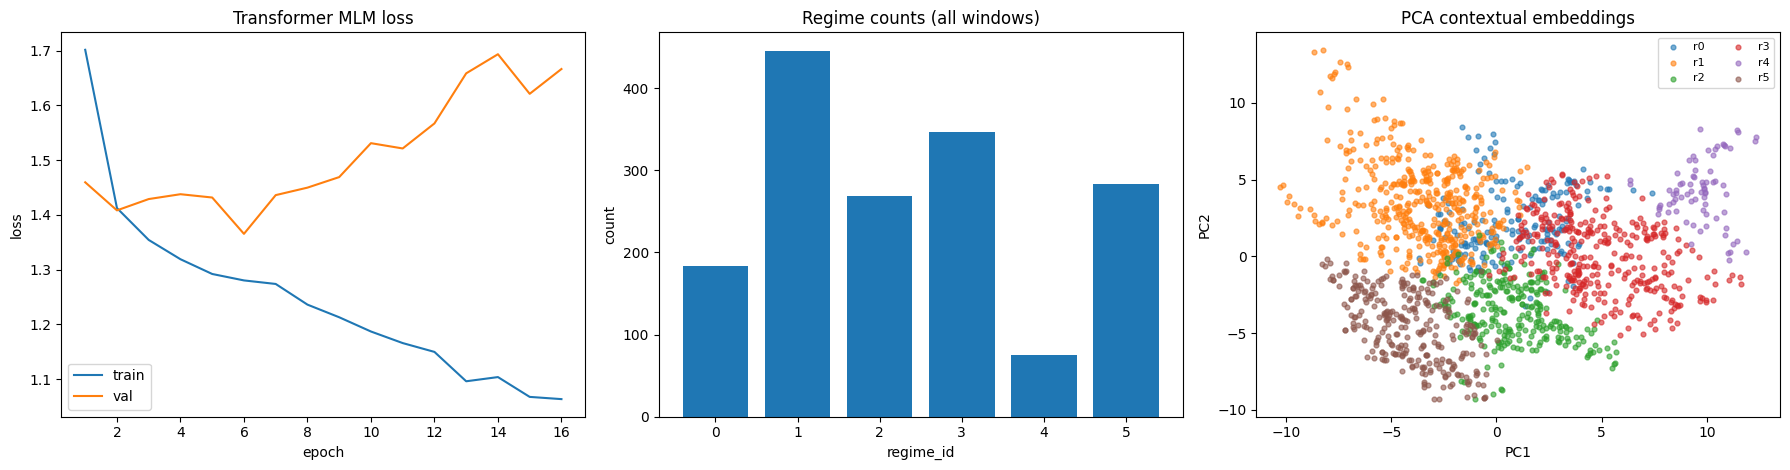

In [10]:
# =========================
# Diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# 1) training curve
axes[0].plot(HIST['epoch'], HIST['train_loss'], label='train')
axes[0].plot(HIST['epoch'], HIST['val_loss'], label='val')
axes[0].set_title('Transformer MLM loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()

# 2) regime counts
cnt = OUT['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (all windows)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

# 3) PCA
pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(Z_all)
for rid in sorted(np.unique(OUT['regime_id'])):
    m = OUT['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=12, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


## Artefactos de salida

- `GBPUSD_transformer_context_encoder.pt`
- `GBPUSD_transformer_context_train_history.csv`
- `GBPUSD_context_window_embeddings.parquet`
- `GBPUSD_superclustering_model_selection.csv`
- `GBPUSD_context_regime_profile.csv`
- `GBPUSD_context_regime_transition_matrix.csv`
- `GBPUSD_superclustering_summary.json`